# 강판 표면 결함 분류 — 최종 모델: 5모델 스태킹

**목표:** 강판 표면 결함 1,941건을 26개 입력 변수로 7개 결함 유형 중 하나로 분류합니다. 클래스 불균형(최다 Other_Faults 673건, 최소 Dirtiness 55건)이 크므로 주 평가 지표는 **Macro F1**입니다.

**최종 모델:** ExtraTrees · LightGBM · XGBoost · HistGradientBoosting · CatBoost의 클래스별 예측 확률을 LogisticRegression이 다시 학습하는 스태킹 모델

| 구분 | 내용 |
|---|---|
| 전처리 | 정답 원-핫 7열 → 라벨 1열, `TypeOfSteel_A300` 제거(A400과 완전 중복), 이상치 유지, 스케일링 없음(트리 모델) |
| 데이터 분할 | `train_test_split(test_size=0.2, stratify=y, random_state=42)` → 개발 1,552행 / 테스트 389행 |
| 메타모델 입력 | 개발 데이터 내부 5-Fold × 3회 반복 OOF 확률 (정답 누수 없음) |
| 모델 선택 기준 | 테스트셋이 아닌 **중첩 교차검증**(전체 데이터 5-Fold × 2회 = 10개 분할) |

**결과 요약**

| 평가 | 기존 ET+LightGBM 스태킹 | 최종 5모델 스태킹 |
|---|---|---|
| 중첩 교차검증 10개 분할 평균 Macro F1 | 0.8339 | **0.8384** |
| 테스트셋(389행) Macro F1 | 0.8256 | **0.8316** |
| 테스트셋 Accuracy | 0.8046 | **0.8098** |

**실행 방법:** `Faults.NNA`, `Faults27x7_var`를 노트북과 같은 폴더에 두고 위에서부터 실행합니다. 필요 패키지는 `lightgbm xgboost catboost scikit-learn matplotlib`입니다. 2절 중첩 교차검증은 약 25분 걸리며, `RUN_NESTED=False`로 두면 건너뛰고 저장된 `stage9_nested_cv.csv`를 사용합니다.

In [1]:
# 필요한 경우: %pip install lightgbm xgboost catboost scikit-learn pandas numpy
import warnings, time
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, RepeatedStratifiedKFold, cross_val_predict
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
warnings.filterwarnings('ignore')

RUN_NESTED = True   # 중첩 CV(시간 소요) 실행 여부
N_JOBS = -1         # 사용할 CPU 코어 수

root = Path('.')
for name in ['Faults.NNA', 'Faults27x7_var']:
    if not (root/name).exists():
        raise FileNotFoundError(f'{name} 파일을 같은 폴더에 두세요. 현재 폴더: {root.resolve()}')
cols = [x.strip() for x in (root/'Faults27x7_var').read_text(encoding='utf-8').splitlines() if x.strip()]
raw = pd.read_csv(root/'Faults.NNA', sep=r'\s+', header=None, names=cols)
assert raw.shape == (1941, 34)
encoder = LabelEncoder()
y_full = encoder.fit_transform(raw[cols[27:]].idxmax(axis=1))
X_full = raw.iloc[:, :27].drop(columns='TypeOfSteel_A300')   # 기존과 동일한 26개 변수
CLASSES = list(encoder.classes_)
macro = lambda a, b: f1_score(a, b, average='macro', zero_division=0)
print('X:', X_full.shape, '| 클래스:', CLASSES)

X: (1941, 26) | 클래스: ['Bumps', 'Dirtiness', 'K_Scatch', 'Other_Faults', 'Pastry', 'Stains', 'Z_Scratch']


## 1. 베이스 모델과 스태킹 함수
- ExtraTrees·LightGBM은 이전 단계 무작위 탐색에서 고른 설정을 그대로 사용했습니다(ExtraTrees는 트리 수만 500 → 1000).
- XGBoost·HistGradientBoosting·CatBoost는 오류 패턴이 서로 달라 스태킹에서 보완 효과를 내도록 추가했습니다. `class_weight='balanced'`를 적용한 HistGradientBoosting은 소수 클래스 재현율이 높아 ExtraTrees와 결합했을 때 개선 폭이 가장 컸습니다.
- `stack_fit_predict`는 학습 데이터 내부의 OOF 확률로만 메타모델을 학습합니다. OOF를 서로 다른 Fold 분할로 3회 반복해 쌓은 이유는, 1회만 만들 경우 Fold 분할에 따라 테스트 점수가 ±0.01 흔들렸기 때문입니다.

In [2]:
def base_models():
    return {
        'ET': ExtraTreesClassifier(n_estimators=1000, min_samples_split=5, max_features=0.8,
                                   class_weight='balanced_subsample', random_state=42, n_jobs=N_JOBS),
        'LGB': LGBMClassifier(objective='multiclass', n_estimators=700, learning_rate=0.05, num_leaves=22,
                              min_child_samples=5, subsample=0.8, subsample_freq=1, colsample_bytree=0.6,
                              reg_lambda=0, random_state=42, n_jobs=N_JOBS, verbose=-1),
        'XGB': XGBClassifier(n_estimators=600, learning_rate=0.03, max_depth=5, subsample=0.8,
                             colsample_bytree=0.6, random_state=42, n_jobs=N_JOBS),
        'HGB': HistGradientBoostingClassifier(max_iter=500, learning_rate=0.05, max_leaf_nodes=15,
                                              l2_regularization=1.0, class_weight='balanced', random_state=42),
        'CAT': CatBoostClassifier(iterations=1000, depth=6, learning_rate=0.05, l2_leaf_reg=3,
                                  loss_function='MultiClass', random_seed=42, verbose=False,
                                  thread_count=N_JOBS, allow_writing_files=False),
    }

OLD = ['ET', 'LGB']                          # 기존 스태킹
NEW = ['ET', 'LGB', 'XGB', 'HGB', 'CAT']     # 9단계 스태킹


def stack_fit_predict(Xa, ya, Xv, names, n_repeats=3, seed=1):
    """Xa로만 학습하고 Xv를 예측. 메타모델은 Xa 내부의 반복 OOF 확률로만 학습(누수 없음)."""
    models = base_models()
    oof = {n: [] for n in names}
    for r in range(n_repeats):
        cv = StratifiedKFold(5, shuffle=True, random_state=seed + r)
        for n in names:
            oof[n].append(cross_val_predict(clone(models[n]), Xa, ya, cv=cv, method='predict_proba'))
    Z = np.vstack([np.hstack([oof[n][r] for n in names]) for r in range(n_repeats)])
    meta = LogisticRegression(C=1.0, max_iter=5000).fit(Z, np.tile(ya, n_repeats))
    test_proba = {n: clone(models[n]).fit(Xa, ya).predict_proba(Xv) for n in names}
    Zv = np.hstack([test_proba[n] for n in names])
    return meta.predict(Zv), test_proba
print('준비 완료')

준비 완료


## 2. 중첩 교차검증 — 모델 선택
389행 테스트셋 하나의 점수는 분할에 따라 크게 달라지므로(같은 모델로 0.80~0.86), 모델 선택은 중첩 교차검증으로 했습니다.
- 전체 1,941행을 5-Fold × 2회 반복으로 나눠 **10번의 '학습 80% / 평가 20%' 실험**을 합니다.
- 각 실험에서 기존 스태킹과 5모델 스태킹을 같은 데이터로 학습·평가하며, 평가 20%는 베이스·메타모델 학습 어디에도 쓰이지 않습니다.
- 계산 시간을 줄이기 위해 이 절에서만 OOF 반복을 1회로 둡니다(최종 모델은 3회).

In [3]:
if not RUN_NESTED and Path('stage9_nested_cv.csv').exists():
    nested = pd.read_csv('stage9_nested_cv.csv', index_col=0)
    print('저장된 중첩 교차검증 결과를 불러왔습니다.')
if RUN_NESTED:
    outer = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=2026)
    rows = []
    for k, (tr, te) in enumerate(outer.split(X_full, y_full), 1):
        t0 = time.time()
        Xa, Xv, ya, yv = X_full.iloc[tr], X_full.iloc[te], y_full[tr], y_full[te]
        p_new, proba = stack_fit_predict(Xa, ya, Xv, NEW, n_repeats=1)
        # 기존 스태킹: 같은 베이스 확률 중 ET, LGB만 사용 (재학습 결과 동일)
        models = base_models(); cv = StratifiedKFold(5, shuffle=True, random_state=1)
        Z_old = np.hstack([cross_val_predict(clone(models[n]), Xa, ya, cv=cv, method='predict_proba') for n in OLD])
        p_old = LogisticRegression(C=1.0, max_iter=5000).fit(Z_old, ya).predict(np.hstack([proba[n] for n in OLD]))
        rows.append({'실험': k, '기존 ET+LGB 스태킹': macro(yv, p_old), '9단계 5모델 스태킹': macro(yv, p_new),
                     **{f'{n} 단독': macro(yv, proba[n].argmax(1)) for n in NEW}})
        print(f'실험 {k:2d} | 기존={rows[-1]["기존 ET+LGB 스태킹"]:.4f} | 9단계={rows[-1]["9단계 5모델 스태킹"]:.4f} | {time.time()-t0:.0f}s', flush=True)
    nested = pd.DataFrame(rows).set_index('실험')
    nested.to_csv('stage9_nested_cv.csv', encoding='utf-8-sig')
    summary = pd.DataFrame({'평균 Macro F1': nested.mean(), '표준편차': nested.std(),
                            '최소': nested.min(), '최대': nested.max(),
                            '0.836 이상 비율': (nested >= 0.836).mean()}).sort_values('평균 Macro F1', ascending=False)
    display(summary.round(4))
    d = nested['9단계 5모델 스태킹'] - nested['기존 ET+LGB 스태킹']
    print(f'9단계 - 기존: 평균 {d.mean():+.4f}, 9단계 우세 {int((d>0).sum())}/{len(d)}회')

실험  1 | 기존=0.8354 | 9단계=0.8401 | 155s


실험  2 | 기존=0.8444 | 9단계=0.8424 | 153s


실험  3 | 기존=0.8101 | 9단계=0.8049 | 152s


실험  4 | 기존=0.8388 | 9단계=0.8648 | 154s


실험  5 | 기존=0.8442 | 9단계=0.8485 | 154s


...

실험  8 | 기존=0.8375 | 9단계=0.8432 | 157s


실험  9 | 기존=0.8421 | 9단계=0.8577 | 164s


실험 10 | 기존=0.8021 | 9단계=0.8175 | 154s


,평균 Macro F1,표준편차,최소,최대,0.836 이상 비율
9단계 5모델 스태킹,0.8384,0.0179,0.8049,0.8648,0.7
기존 ET+LGB 스태킹,0.8339,0.0151,0.8021,0.8462,0.7
HGB 단독,0.8310,0.0181,0.8079,0.8717,0.2
ET 단독,0.8309,0.0141,0.8020,0.8475,0.4
LGB 단독,0.8262,0.0157,0.7947,0.8427,0.3
XGB 단독,0.8204,0.0168,0.7908,0.8411,0.2
CAT 단독,0.8194,0.0137,0.7923,0.8423,0.1


9단계 - 기존: 평균 +0.0046, 9단계 우세 6/10회


## 3. 최종 모델 학습 및 테스트셋 평가
개발 1,552행으로만 학습하고, 389행 테스트셋은 여기서 한 번만 평가합니다. 비교를 위해 기존 ET+LightGBM 스태킹과 각 베이스 모델 단독 성능도 같은 조건에서 계산합니다.

In [4]:
idx_dev, idx_test = train_test_split(np.arange(len(y_full)), test_size=0.2, stratify=y_full, random_state=42)
X_dev, y_dev = X_full.iloc[idx_dev], y_full[idx_dev]
X_test, y_test = X_full.iloc[idx_test], y_full[idx_test]

pred_new, test_proba = stack_fit_predict(X_dev, y_dev, X_test, NEW, n_repeats=3)
pred_old, _ = stack_fit_predict(X_dev, y_dev, X_test, OLD, n_repeats=3)

final = pd.DataFrame([
    {'모델': '기존 ET+LGB 스태킹 (반복 OOF)', 'Test Macro F1': macro(y_test, pred_old), 'Accuracy': accuracy_score(y_test, pred_old)},
    {'모델': '9단계 5모델 스태킹', 'Test Macro F1': macro(y_test, pred_new), 'Accuracy': accuracy_score(y_test, pred_new)},
] + [{'모델': f'{n} 단독', 'Test Macro F1': macro(y_test, p.argmax(1)), 'Accuracy': accuracy_score(y_test, p.argmax(1))}
     for n, p in test_proba.items()])
display(final.round(4))

rng = np.random.default_rng(42)
boot = [macro(y_test[b], pred_new[b]) for b in (rng.integers(0, len(y_test), len(y_test)) for _ in range(1000))]
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f'9단계 Test Macro F1 95% 부트스트랩 신뢰구간: [{lo:.3f}, {hi:.3f}]')
final.to_csv('stage9_final_test.csv', index=False, encoding='utf-8-sig')

,모델,Test Macro F1,Accuracy
0,기존 ET+LGB 스태킹 (반복 OOF),0.8256,0.8046
1,9단계 5모델 스태킹,0.8316,0.8098
2,ET 단독,0.8199,0.7969
3,LGB 단독,0.8111,0.8021
4,XGB 단독,0.8140,0.8046
5,HGB 단독,0.8080,0.7969
6,CAT 단독,0.8145,0.7969


9단계 Test Macro F1 95% 부트스트랩 신뢰구간: [0.787, 0.869]


In [5]:
labs = np.arange(len(CLASSES))
print(classification_report(y_test, pred_new, labels=labs, target_names=CLASSES, digits=4, zero_division=0))
display(pd.DataFrame(confusion_matrix(y_test, pred_new), index=CLASSES, columns=CLASSES))
cmp = pd.DataFrame({'기존': f1_score(y_test, pred_old, average=None, labels=labs),
                    '9단계': f1_score(y_test, pred_new, average=None, labels=labs)}, index=CLASSES)
cmp['변화'] = cmp['9단계'] - cmp['기존']
display(cmp.round(4))

              precision    recall  f1-score   support

       Bumps     0.7568    0.6914    0.7226        81
   Dirtiness     1.0000    0.9091    0.9524        11
    K_Scatch     0.9737    0.9487    0.9610        78
Other_Faults     0.7255    0.8222    0.7708       135
      Pastry     0.6071    0.5312    0.5667        32
      Stains     0.9231    0.8571    0.8889        14
   Z_Scratch     1.0000    0.9211    0.9589        38

    accuracy                         0.8098       389
   macro avg     0.8552    0.8115    0.8316       389
weighted avg     0.8137    0.8098    0.8099       389



,Bumps,Dirtiness,K_Scatch,Other_Faults,Pastry,Stains,Z_Scratch
Bumps,56,0,0,22,3,0,0
Dirtiness,0,10,0,1,0,0,0
K_Scatch,1,0,74,3,0,0,0
Other_Faults,14,0,1,111,8,1,0
Pastry,2,0,0,13,17,0,0
Stains,1,0,0,1,0,12,0
Z_Scratch,0,0,1,2,0,0,35


,기존,9단계,변화
Bumps,0.7059,0.7226,0.0167
Dirtiness,0.9524,0.9524,0.0000
K_Scatch,0.9474,0.9610,0.0137
Other_Faults,0.7713,0.7708,-0.0005
Pastry,0.5862,0.5667,-0.0195
Stains,0.8571,0.8889,0.0317
Z_Scratch,0.9589,0.9589,0.0000


## 4. 최종 모델 시각화
4-1 혼동행렬 · 4-2 클래스별 F1 비교 · 4-3 중첩 교차검증 분할별 성능 · 4-4 변수 중요도 순서로 봅니다.

In [6]:
import matplotlib.pyplot as plt
from matplotlib import font_manager

# 한글 글꼴: 설치된 것 중 첫 번째를 사용
for f in ['Malgun Gothic', 'AppleGothic', 'NanumGothic', 'Noto Sans CJK KR']:
    if f in {x.name for x in font_manager.fontManager.ttflist}:
        plt.rcParams['font.family'] = f
        break
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

BLUE, GREY, INK, MUTED = '#2a6fdb', '#b9b9b2', '#222222', '#6b6b6b'
if 'nested' not in globals() and Path('stage9_nested_cv.csv').exists():
    nested = pd.read_csv('stage9_nested_cv.csv', index_col=0)

### 4-1. 혼동행렬
왼쪽은 건수, 오른쪽은 실제 클래스별 비율(행 기준, 대각선 = 재현율)입니다.

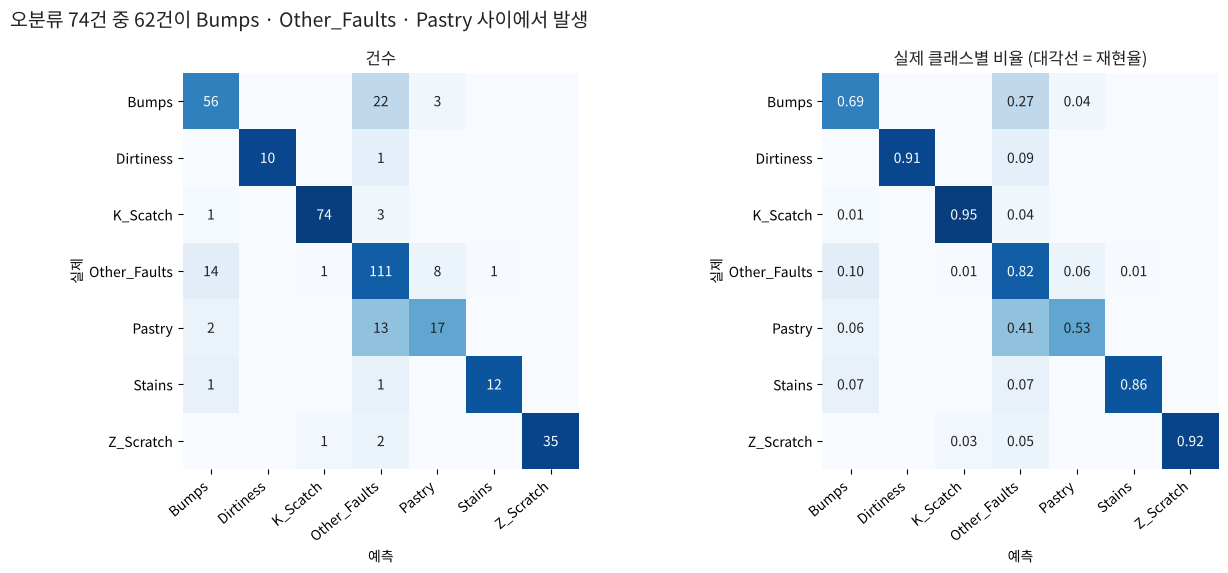

In [7]:
cm = confusion_matrix(y_test, pred_new, labels=labs)
cm_rate = cm / cm.sum(axis=1, keepdims=True)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.8))
for ax, mat, title, fmt in [(axes[0], cm, '건수', 'd'), (axes[1], cm_rate, '실제 클래스별 비율 (대각선 = 재현율)', '.2f')]:
    ax.imshow(cm_rate, cmap='Blues', vmin=0, vmax=1)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            v = mat[i, j]
            if v == 0:
                continue
            ax.text(j, i, format(v, fmt), ha='center', va='center', fontsize=10,
                    color='white' if cm_rate[i, j] > 0.55 else INK)
    ax.set_xticks(labs, CLASSES, rotation=40, ha='right')
    ax.set_yticks(labs, CLASSES)
    ax.set_xlabel('예측'); ax.set_ylabel('실제')
    ax.set_title(title, fontsize=12, color=INK)
    for s in ax.spines.values():
        s.set_visible(False)
off = cm.sum() - np.trace(cm)
hard = [CLASSES.index(c) for c in ['Bumps', 'Other_Faults', 'Pastry']]
hard_err = sum(cm[i, j] for i in hard for j in hard if i != j)
fig.suptitle(f'오분류 {off}건 중 {hard_err}건이 Bumps · Other_Faults · Pastry 사이에서 발생', fontsize=14, x=0.01, ha='left', color=INK)
plt.tight_layout()
plt.savefig('stage9_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

### 4-2. 클래스별 F1 — 기존 대비

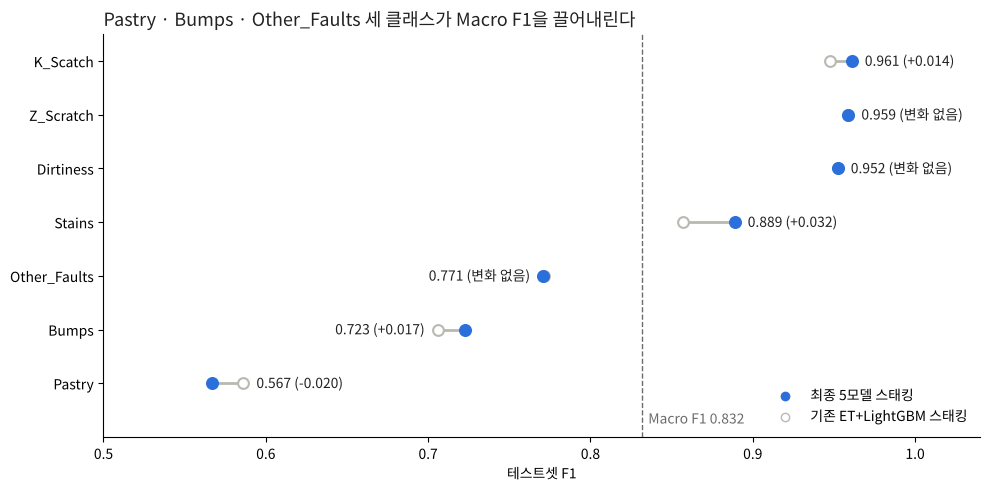

In [8]:
order = cmp['9단계'].sort_values().index
y = np.arange(len(order))
macro_new = cmp['9단계'].mean()
fig, ax = plt.subplots(figsize=(10, 5))
for i, c in enumerate(order):
    o, n = cmp.loc[c, '기존'], cmp.loc[c, '9단계']
    ax.plot([o, n], [i, i], color=GREY, lw=2, zorder=1)
    ax.scatter(o, i, s=60, facecolor='white', edgecolor=GREY, lw=1.5, zorder=2)
    ax.scatter(n, i, s=70, color=BLUE, zorder=3)
    d = n - o
    label = f'{n:.3f} ({d:+.3f})' if abs(d) >= 0.0005 else f'{n:.3f} (변화 없음)'
    left = max(o, n) < macro_new and max(o, n) + 0.12 > macro_new   # 오른쪽에 쓰면 기준선과 겹치는 경우
    ax.text(min(o, n) - 0.008 if left else max(o, n) + 0.008, i, label, va='center',
            ha='right' if left else 'left', fontsize=10, color=INK)
ax.axvline(macro_new, color=MUTED, ls='--', lw=1)
ax.text(macro_new + 0.004, -0.75, f'Macro F1 {macro_new:.3f}', fontsize=10, color=MUTED)
ax.set_yticks(y, order)
ax.set_xlim(0.5, 1.04)
ax.set_ylim(-1, len(order) - 0.5)
ax.set_xlabel('테스트셋 F1')
ax.scatter([], [], color=BLUE, label='최종 5모델 스태킹')
ax.scatter([], [], facecolor='white', edgecolor=GREY, label='기존 ET+LightGBM 스태킹')
ax.legend(loc='lower right', frameon=False)
ax.set_title('Pastry · Bumps · Other_Faults 세 클래스가 Macro F1을 끌어내린다', loc='left', fontsize=13, color=INK)
plt.tight_layout()
plt.savefig('stage9_class_f1.png', dpi=150, bbox_inches='tight')
plt.show()

### 4-3. 중첩 교차검증 분할별 성능
같은 모델이라도 분할에 따라 점수가 크게 달라지며, 고정 테스트셋(`random_state=42`)은 평균보다 어려운 분할입니다.

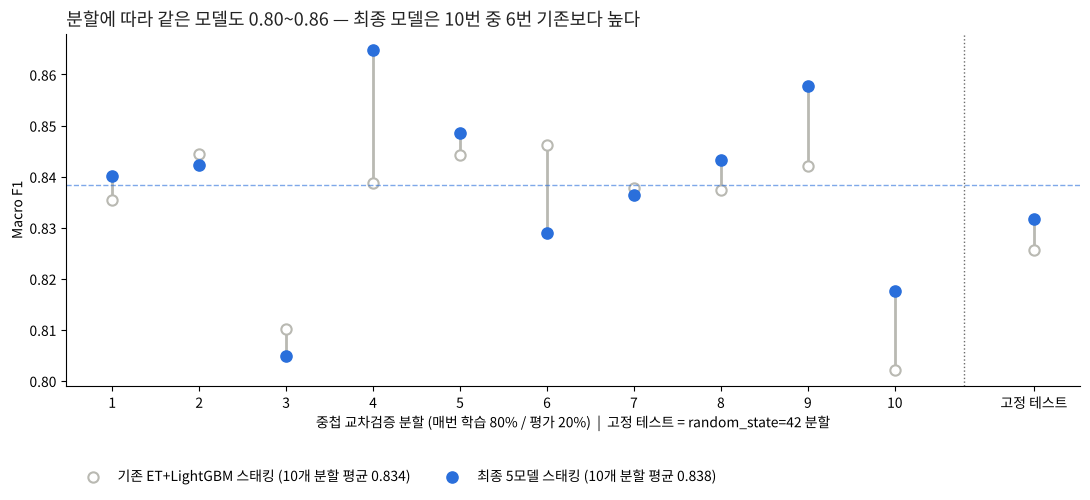

In [9]:
cols_ = ['기존 ET+LGB 스태킹', '9단계 5모델 스태킹']
old_s = list(nested[cols_[0]]) + [macro(y_test, pred_old)]
new_s = list(nested[cols_[1]]) + [macro(y_test, pred_new)]
labels_ = [str(i) for i in nested.index] + ['고정 테스트']
x = np.arange(len(labels_)) + np.r_[np.zeros(len(nested)), 0.6]
fig, ax = plt.subplots(figsize=(11, 5.2))
for xi, o, n in zip(x, old_s, new_s):
    ax.plot([xi, xi], [o, n], color=GREY, lw=2, zorder=1)
ax.scatter(x, old_s, s=55, facecolor='white', edgecolor=GREY, lw=1.5, zorder=2,
           label=f'기존 ET+LightGBM 스태킹 (10개 분할 평균 {nested[cols_[0]].mean():.3f})')
ax.scatter(x, new_s, s=65, color=BLUE, zorder=3,
           label=f'최종 5모델 스태킹 (10개 분할 평균 {nested[cols_[1]].mean():.3f})')
ax.axhline(nested[cols_[1]].mean(), color=BLUE, ls='--', lw=1, alpha=0.6)
ax.axvline(x[-1] - 0.8, color=MUTED, ls=':', lw=1)
ax.set_xticks(x, labels_)
ax.set_xlabel('중첩 교차검증 분할 (매번 학습 80% / 평가 20%)  |  고정 테스트 = random_state=42 분할')
ax.set_ylabel('Macro F1')
ax.legend(loc='upper left', bbox_to_anchor=(0, -0.2), ncol=2, frameon=False, fontsize=10)
ax.set_title('분할에 따라 같은 모델도 0.80~0.86 — 최종 모델은 10번 중 6번 기존보다 높다', loc='left', fontsize=13, color=INK)
plt.tight_layout()
plt.savefig('stage9_nested_cv.png', dpi=150, bbox_inches='tight')
plt.show()

### 4-4. 변수 중요도 (ExtraTrees)
스태킹 전체의 중요도는 직접 계산하기 어려워, 베이스 모델 중 단독 성능이 가장 높은 ExtraTrees를 개발 데이터로 학습해 불순도 기반 중요도를 확인합니다.

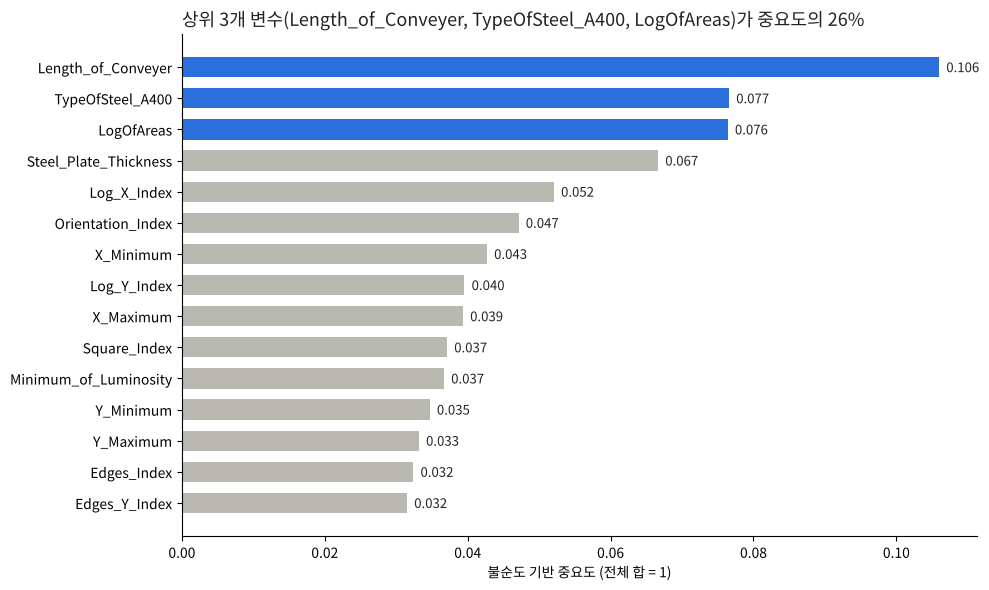

,중요도
Length_of_Conveyer,0.1060
TypeOfSteel_A400,0.0766
LogOfAreas,0.0764
Steel_Plate_Thickness,0.0667
Log_X_Index,0.0521
Orientation_Index,0.0471
X_Minimum,0.0427
Log_Y_Index,0.0396
X_Maximum,0.0393
Square_Index,0.0371


In [10]:
et_final = base_models()['ET'].fit(X_dev, y_dev)
imp = pd.Series(et_final.feature_importances_, index=X_dev.columns).sort_values()
top = imp.tail(15)
fig, ax = plt.subplots(figsize=(10, 6))
colors = [BLUE if i >= len(top) - 3 else GREY for i in range(len(top))]
ax.barh(top.index, top.values, color=colors, height=0.65)
for i, v in enumerate(top.values):
    ax.text(v + 0.001, i, f'{v:.3f}', va='center', fontsize=9.5, color=INK)
ax.set_xlabel('불순도 기반 중요도 (전체 합 = 1)')
ax.set_title(f'상위 3개 변수({", ".join(top.index[-3:][::-1])})가 중요도의 {top.tail(3).sum():.0%}', loc='left', fontsize=13, color=INK)
plt.tight_layout()
plt.savefig('stage9_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()
display(imp.sort_values(ascending=False).round(4).to_frame('중요도').head(10))

## 5. 결론
- **최종 모델:** 5모델 스태킹(ExtraTrees · LightGBM · XGBoost · HistGradientBoosting · CatBoost → LogisticRegression)
- **성능:** 테스트셋 Macro F1 **0.8316**(Accuracy 0.8098), 중첩 교차검증 10개 분할 평균 Macro F1 **0.8384**. 두 기준 모두 기존 ET+LightGBM 스태킹(0.8256 / 0.8339)보다 높습니다.
- **신뢰도:** 테스트셋 점수의 부트스트랩 95% 신뢰구간은 [0.787, 0.869]로 넓습니다. 389행 단일 분할보다 10개 분할 평균이 더 안정적인 성능 추정치입니다.
- **한계:** Pastry(F1 0.57)와 Bumps(0.72)는 대부분 Other_Faults와 혼동됩니다. 현재 26개 변수만으로는 개선 여지가 작아, 결함 이미지나 공정 정보 같은 새 변수가 필요합니다.
- **효과가 없었던 시도:** 파생변수 13개, 변수 제거, 클래스별 확률 보정(중첩 교차검증 −0.002), 보조 이진 분류기, 계층형 분류(Other vs 불량 → 불량 6종: 0.836 → 0.821), SVM·MLP·KNN 추가, ExtraTrees 하이퍼파라미터 36개 조합 재탐색.
- **모델 선택 원칙:** 테스트셋은 이전 단계에서 확인한 적이 있으므로, 최종 모델과 설정은 테스트 점수가 아닌 중첩 교차검증 결과로 결정했습니다.